In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from fit_file import X_sq
from fit_file_copy import X_sq2

In [2]:
###ABSORPTIEMETINGEN INLEZEN
#blauw - we hebben maximum nodig → één file inlezen om maximum te bepalen en dan die golflengte manueel zoeken in de files

data_blauw = np.loadtxt(fname = "data/Cuvettes_blauw_Capture20__0__00000.txt", skiprows = 2, delimiter = "\t", dtype = str).T
data_blauw = np.char.replace(data_blauw, ',', '.').astype(float)
print(np.max(data_blauw[1])) #→lambda = 629.089 nm
A_max_blauw = np.array([1.11, 0.88, 0.67, 0.44, 0.21])

#rood

data_rood = np.loadtxt(fname = "data/Cuvettes_rood_Capture36__0__00000.txt", skiprows = 2, delimiter = "\t", dtype = str).T
data_rood = np.char.replace(data_rood, ',', '.').astype(float)
print(np.max(data_rood[1])) #→ lambda = 516.828 nm
A_max_rood = np.array([0.4, 0.32, 0.22, 0.14, 0.04])

#geel

data_geel = np.loadtxt(fname = "data/Curvettes_geel_Capture69__0__00000.txt", skiprows = 2, delimiter = "\t", dtype = str).T
data_geel = np.char.replace(data_geel, ',', '.').astype(float)
print(np.max(data_geel[1])) #→ lambda = 429.784 nm
A_max_geel = np.array([0.32, 0.25, 0.2, 0.11, 0.04])


1.11
0.4
0.32



---------START--------------------------------------------------------------------------------------------------


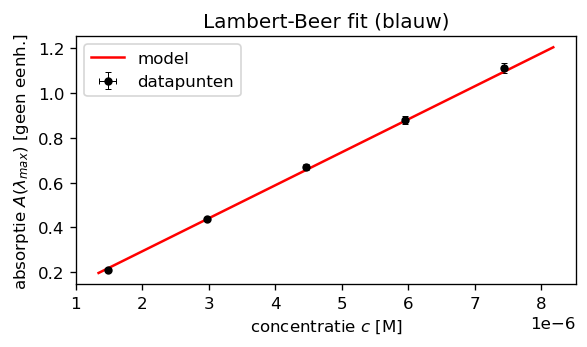

For parameter $\varepsilon l$ :     Minimum at  147034.32953774     ;     68% CI = [ 145723.39850062,  148339.68345018]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           6.45497291
Reduced χ² value       :     χ²_red           1.61374323
P-value                :     p-value          0.16764966


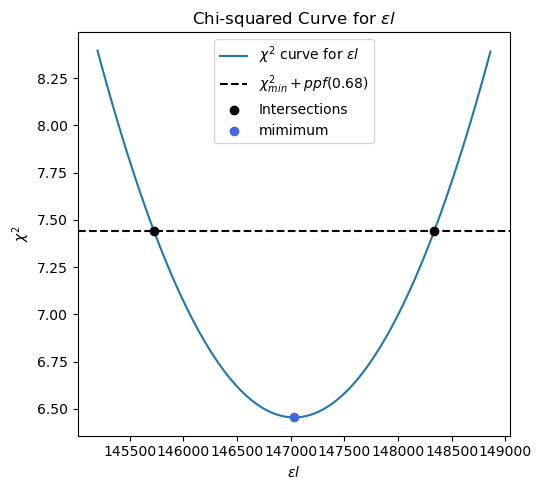

----------END---------------------------------------------------------------------------------------------------

1310.9310371199972


In [3]:
#FITTEN
#blauw
def model(params, c):
    el = params
    return el * c

c_waarden_blauw = np.array([7.44e-6, 5.95e-6, 4.46e-6, 2.98e-6, 1.49e-6])

x = c_waarden_blauw
y = A_max_blauw
dx = np.zeros_like(x) #geen fout op concentraties
dy = 0.02*A_max_blauw

ylabel = r"absorptie $A(\lambda_{max})$ [geen eenh.]"
xlabel = r"concentratie $c$ [M]"

param_names = [r"$\varepsilon l$"]
X_sq(((x, dx), (y, dy)), param_names, initial_guess = [1], model = model, graf1_x_label = xlabel, graf1_y_label = ylabel, graf1_title = "Lambert-Beer fit (blauw)")
print(np.abs(147034.32953774-145723.39850062))


---------START--------------------------------------------------------------------------------------------------


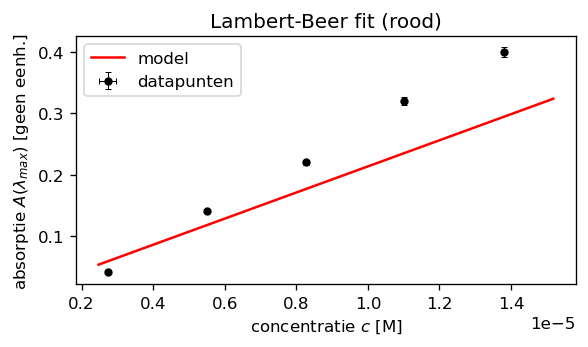

For parameter $\varepsilon l$ :     Minimum at   21335.73661524     ;     68% CI = [  21137.39524257,   21534.15841439]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min        1061.02760586
Reduced χ² value       :     χ²_red         265.25690146
P-value                :     p-value          0.00000000


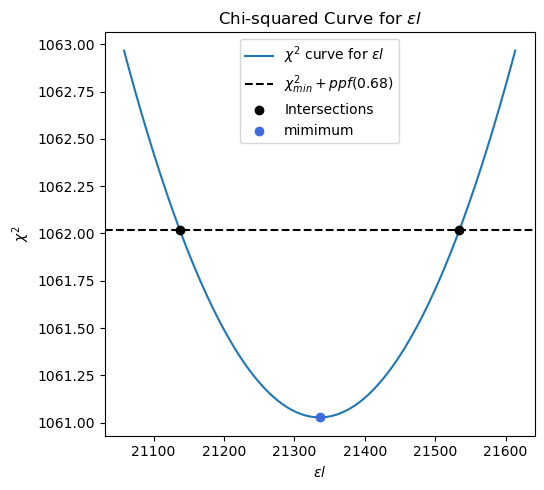

----------END---------------------------------------------------------------------------------------------------

198.34137266999824


In [4]:
#rood
c_waarden_rood = np.array([1.38e-5, 1.1e-5, 8.26e-6, 5.5e-6, 2.75e-6])

x = c_waarden_rood
y = A_max_rood
dx = np.zeros_like(x) #geen fout op concentraties
dy = 0.02*A_max_rood

param_names = [r"$\varepsilon l$"]
X_sq(((x, dx), (y, dy)), param_names, initial_guess = [121335.78435342], model = model, graf1_x_label = r"concentratie $c$ [M]", graf1_y_label = r"absorptie $A(\lambda_{max})$ [geen eenh.]", graf1_title = "Lambert-Beer fit (rood)")
print(np.abs(21335.73661524-21137.39524257))


---------START--------------------------------------------------------------------------------------------------


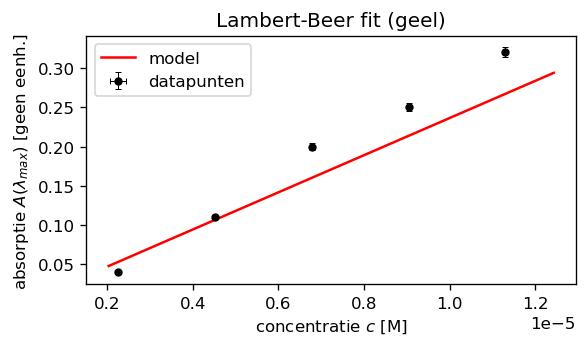

For parameter $\varepsilon l$ :     Minimum at   23643.04966630     ;     68% CI = [  23428.50651102,   23857.83572757]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min         503.25347009
Reduced χ² value       :     χ²_red         125.81336752
P-value                :     p-value          0.00000000


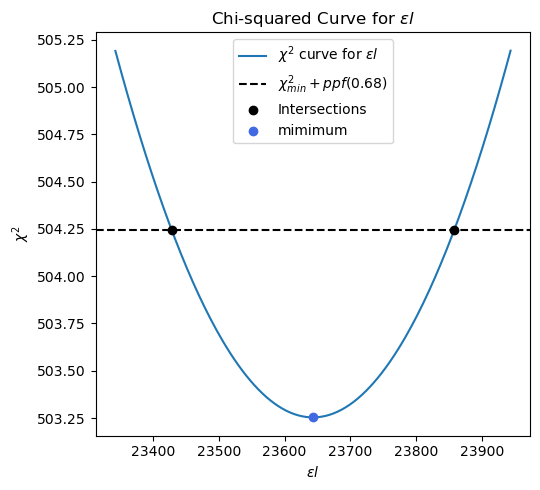

----------END---------------------------------------------------------------------------------------------------

214.54315528000006


In [5]:
#geel
c_waarden_geel = np.array([1.13e-5, 9.04e-6, 6.78e-6, 4.52e-6, 2.26e-6])

x = c_waarden_geel
y = A_max_geel
dx = np.zeros_like(x) #geen fout op concentraties
dy = 0.02*A_max_geel

param_names = [r"$\varepsilon l$"]
X_sq(((x, dx), (y, dy)), param_names, initial_guess = [23643.04965104], model = model, graf1_x_label = r"concentratie $c$ [M]", graf1_y_label = r"absorptie $A(\lambda_{max})$ [geen eenh.]", graf1_title = "Lambert-Beer fit (geel)")
print(np.abs(23643.04966630-23428.50651102))

In [6]:
###EMISSIEMETINGEN - data inlezen

data_helium = np.loadtxt(fname = "data/Heliumspectrum_Subt24__0__15-54-39-926.txt", skiprows = 15, delimiter = "\t", dtype = str).T
data_helium = np.char.replace(data_helium, ',', '.').astype(float)
print(np.max(data_helium[1])) #→ lambda = 587.825 nm

1662.07



---------START--------------------------------------------------------------------------------------------------


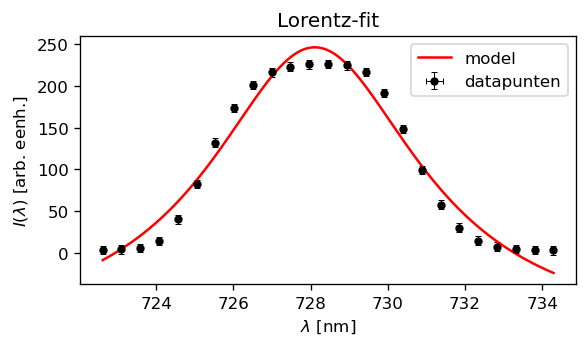

For parameter $A$      :     Minimum at    3682.53630116     ;     68% CI = [   3646.92123971,    3718.15119094]
For parameter $x_0$    :     Minimum at     728.10969602     ;     68% CI = [    728.06353016,     728.15585418]
For parameter $\gamma$ :     Minimum at       3.35008896     ;     68% CI = [      3.30507910,       3.39606244]
For parameter $y_0$    :     Minimum at    -103.65697244     ;     68% CI = [   -105.82386452,    -101.49007989]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min         270.56315989
Reduced χ² value       :     χ²_red          12.88395999
P-value                :     p-value          0.00000000


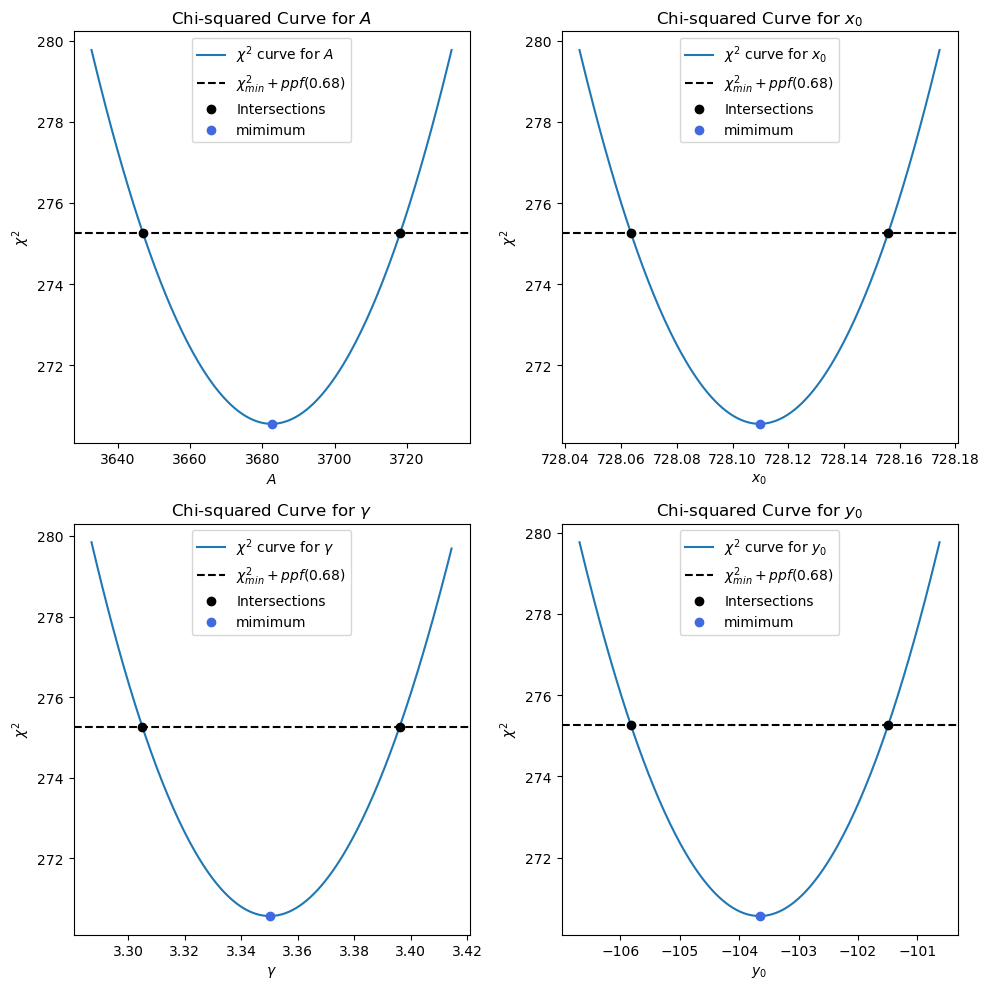

----------END---------------------------------------------------------------------------------------------------

722.615 734.295
35.61506145000021
0.04616585999997369
0.04500985999999996
2.1668920799999967


In [7]:
#fitten van Lorentzprofiel

def model_Lorentz(params, x):
    A, x0, gamma, y0 = params
    return A / np.pi * gamma/((x - x0)**2 + gamma**2) + y0

param_names = [r"$A$", r"$x_0$", r"$\gamma$", r"$y_0$"]

x = data_helium[0][819: 844] #819: 844
y = np.abs(data_helium[1][819: 844])
dx = np.zeros_like(x)
dy = np.array([np.sqrt(len(x)) for i in range(len(x))]) #over nadenken

title = 'Lorentz-fit'
x_label = r'$\lambda$ [nm]'
y_label = r'$I(\lambda)$ [arb. eenh.]'

X_sq2(((x, dx), (y, dy)), param_names, (2200.15010953, 728.10724696, 2.48882790, 28), model_Lorentz, graf1_title= title, graf1_x_label= x_label, graf1_y_label=y_label)
print(np.min(x), np.max(x))

print(np.abs(3682.53630116 - 3646.92123971))
print(np.abs(728.10969602 - 728.06353016))
print(np.abs(3.35008896 - 3.30507910))
print(np.abs(-103.65697244 - (-105.82386452)))

In [8]:
###mystery cuvettes

data_M1 = np.loadtxt(fname = "data/M1_Absorbance__0__00001.txt", skiprows = 15, delimiter = "\t", dtype = str).T
data_M1 = np.char.replace(data_M1, ',', '.').astype(float)

data_M51 = np.loadtxt(fname = "data/M51_Absorbance__0__00000.txt", skiprows = 15, delimiter = "\t", dtype = str).T
data_M51 = np.char.replace(data_M51, ',', '.').astype(float)

In [9]:
el_blauw = 147034.32953774
el_geel = 23643.04966630
el_rood = 21335.73661524

#M1 = groen = geel + blauw
A_geel_M1 = 0.14 #lambda = 412 nm
A_blauw_M1 = 0.28 #lambda = 629 nm

c_geel_M1 = A_geel_M1 / el_geel
c_blauw_M1 = A_blauw_M1 / el_blauw

#M1 = oranje = geel + rood
A_geel_M51 = 0.15 #lambda = 446 nm
A_rood_M51 = 0.16 #lambda = 516 nm
c_geel_M51 = A_geel_M51 / el_geel
c_rood_M51 = A_rood_M51 / el_rood

print(c_geel_M1, c_blauw_M1, c_geel_M51, c_rood_M51)


5.9214019331673295e-06 1.9043171814384415e-06 6.344359214107852e-06 7.4991551913756234e-06


In [10]:
#fouten
el_geel_fout = np.abs(el_geel - 23428.50651102)
el_rood_fout = np.abs(el_rood - 21137.39524257)
el_blauw_fout = np.abs(el_blauw - 145723.39850062)

def fout_c(el_val, el_err, A_val, dA):
    c = sp.Function('c')
    A, el = sp.symbols('A el')
    c = A / el
    s_func = sp.sqrt((sp.diff(c, el))**2 * el_err**2 + (sp.diff(c, A))**2 * dA**2)
    s = s_func.subs([(el, el_val), (A, A_val)])
    return s

c_fout_geelM1 = fout_c(el_geel, el_geel_fout, A_geel_M1, 0.02*A_geel_M1)
c_fout_blauwM1 = fout_c(el_blauw, el_blauw_fout, A_blauw_M1, 0.02*A_blauw_M1)

c_fout_geelM51 = fout_c(el_geel, el_geel_fout, A_geel_M51, 0.02*A_geel_M51)
c_fout_roodM51 = fout_c(el_rood, el_rood_fout, A_rood_M51, 0.02*A_rood_M51)
print(c_fout_geelM1, c_fout_blauwM1, c_fout_geelM51, c_fout_roodM51)

1.30047545604321e-7 4.16994058685968e-8 1.39336656004630e-7 1.65393254822329e-7
